# Livrable de modélisation
## Modélisation du problème de tournées de livraison
### Le CVRPTW : formalisation, graphe et complexité

*Réponse à l'appel à manifestation d'intérêt de l'ADEME · Équipe CesiCDP · 12 octobre 2026*

---

> **En bref**
>
> - Il faut organiser les tournées de plusieurs camions pour livrer des clients, en respectant la **capacité** des camions et le **créneau horaire** de chaque client, avec une distance totale la plus petite possible.
> - Ce problème s'appelle le **CVRPTW** (*Capacitated Vehicle Routing Problem with Time Windows*).
> - On le représente par un **graphe orienté complet pondéré** : des points (dépôt, clients) reliés par des flèches qui portent un temps de trajet.
> - Il est **NP-difficile** : aucun algorithme rapide n'est connu pour le résoudre exactement. Pour plusieurs milliers de clients, on utilisera donc une métaheuristique.

**Sommaire**

1. Contexte et objectif
2. Le problème avec des mots simples
3. Les données du problème
4. Représentation par un graphe
5. Les contraintes
6. L'objectif à optimiser
7. Combien de solutions possibles ?
8. Classe du problème et complexité
9. Modèle PLNE (première version)
10. Conséquences pour la suite du projet
11. Glossaire
12. Références

## 1. Contexte et objectif

L'ADEME (Agence de l'Environnement et de la Maîtrise de l'Énergie) cherche des solutions pour mieux organiser le transport des personnes et des marchandises. Notre équipe, au sein de CesiCDP, répond à cet appel en étudiant un cas très concret : **la gestion de tournées de livraison**.

Le problème est le suivant : un dépôt, des clients à livrer, plusieurs camions. Il faut décider **quel camion livre quels clients, et dans quel ordre**, pour que la durée totale de conduite soit minimale. Cela intéresse l'environnement, car moins de kilomètres parcourus veut dire moins de carburant consommé et moins de pollution.

Notre version du problème ajoute **une seule contrainte supplémentaire** à la version de base (flotte de $k$ camions de capacité identique) : les **fenêtres de temps** de livraison. Ce document répond à l'étape « Modélisation » de la feuille de route : présenter le problème, le représenter par un graphe, étudier sa **complexité** et en donner une première **modélisation PLNE**. La résolution (méthode exacte, métaheuristique, application) viendra dans les étapes suivantes.

## 2. Le problème avec des mots simples

Imaginons un livreur de colis. Le matin, il charge son camion au dépôt. Il doit ensuite livrer plusieurs clients, puis revenir au dépôt. Trois règles s'imposent à lui :

- **Son camion a une limite de charge** : il ne peut pas transporter plus de $Q$ colis (capacité).
- **Chaque client a un créneau** : par exemple « livrez-moi entre 9h45 et 11h00 ». Arriver trop tard est interdit. Arriver trop tôt oblige à attendre devant la porte.
- **Chaque client est livré une seule fois**, par un seul camion.

Comme un seul camion ne suffit pas toujours (capacité limitée), l'entreprise en utilise plusieurs. Le travail de l'ingénieur est de **répartir les clients** entre les camions et de **choisir l'ordre de passage** de chacun. C'est exactement ce que fait un logiciel de planification de tournées.

## 3. Les données du problème

Pour qu'un ordinateur puisse traiter le problème, on le décrit avec des **symboles mathématiques**. Le tableau ci-dessous donne le vocabulaire utilisé dans tout le document. La dernière colonne reprend l'exemple de la figure 1, avec 6 clients.

| Élément | Notation | Signification | Dans l'exemple |
|---|---|---|---|
| Dépôt | $0$ | Point de départ et d'arrivée de tous les camions | 1 dépôt |
| Clients | $1, 2, \dots, n$ | Lieux où il faut livrer | $n = 6$ (C1 à C6) |
| Sommets | $V = \{0, 1, \dots, n\}$ | Le dépôt et tous les clients | 7 sommets |
| Camions | $k$ | Nombre maximal de camions (tous identiques) | $k = 3$ |
| Capacité | $Q$ | Charge maximale d'un camion | $Q = 15$ |
| Demande | $q_i$ | Quantité à livrer au client $i$ | $q_1 = 4$, $q_2 = 6$, ... |
| Fenêtre de temps | $[a_i, b_i]$ | Heure d'ouverture $a_i$ et heure limite $b_i$ chez le client $i$ | C1 : [8h30, 10h00] |
| Durée de service | $s_i$ | Temps passé à décharger chez le client $i$ | 10 min pour chaque client |
| Temps de trajet | $t_{ij}$ | Durée du trajet du point $i$ vers le point $j$ | Dépôt → C1 : 43 min |

**Hypothèses de modélisation**

| Hypothèse | Pourquoi |
|---|---|
| $t_{ij}$ est la durée du **plus court chemin** routier de $i$ à $j$ | On ne garde que les lieux utiles (dépôt, clients) : le réseau routier complet se résume à un graphe complet. Conséquence : $t_{ij} \le t_{il} + t_{lj}$ (inégalité triangulaire). |
| Un client est livré **en une seule fois** | Pas de livraison fractionnée entre plusieurs camions. |
| $q_i \le Q$ pour tout client | Sinon aucun camion ne pourrait livrer ce client. |
| Temps de trajet **constants** | Le trafic par tranche horaire est discuté en section 6. |

L'exemple de la figure 1, sous forme de données Python. Ces valeurs sont reprises du graphe ; seuls les temps des arcs utilisés par les tournées sont connus.

In [1]:
# Données de l'exemple (figure 1). Heures en minutes depuis minuit.
def h(heure, minute=0):
    return heure * 60 + minute

def fmt(m):
    return f"{int(m // 60)}h{int(m % 60):02d}"

Q, k = 15, 3
depart_depot = h(8)
service = 10

clients = {           # demande q, fenêtre [a, b]
    "C1": (4, h(8, 30), h(10, 0)),
    "C2": (6, h(9, 45), h(11, 0)),
    "C3": (3, h(8, 30), h(9, 30)),
    "C4": (5, h(9, 0), h(10, 30)),
    "C5": (7, h(8, 30), h(9, 30)),
    "C6": (2, h(9, 15), h(10, 30)),
}

# Temps de trajet t_ij (minutes) des arcs utilisés
t = {("D", "C1"): 43, ("C1", "C2"): 38, ("C2", "D"): 39,
     ("D", "C3"): 44, ("C3", "C4"): 36, ("C4", "D"): 40,
     ("D", "C5"): 41, ("C5", "C6"): 35, ("C6", "D"): 45}

tournees = [["C1", "C2"], ["C3", "C4"], ["C5", "C6"]]
print(f"{len(clients)} clients, k = {k} camions, Q = {Q}")

6 clients, k = 3 camions, Q = 15


## 4. Représentation par un graphe

### 4.1 Qu'est-ce qu'un graphe ?

Un **graphe** est un schéma très simple : des **sommets** (des points) et des **arcs** (des flèches entre les points). Chaque arc peut porter un nombre, appelé **poids**. Le plan d'un réseau de métro est un graphe : les stations sont les sommets, les tronçons sont les arcs, et le poids est le temps de trajet.

### 4.2 Notre graphe

Nous modélisons notre problème par le graphe $G = (V, A)$ défini ainsi :

| Élément | Définition |
|---|---|
| **Sommets** | Le dépôt et les clients. Chaque client porte ses informations ($q_i$, $[a_i, b_i]$, $s_i$). |
| **Arcs** | Une flèche de chaque point vers chaque autre point : $A = \{(i, j) \in V^2,\ i \neq j\}$. Le graphe est donc **complet**, car on peut toujours aller d'un point à n'importe quel autre en passant par le réseau routier. |
| **Poids** | Le temps de trajet $t_{ij}$ de $i$ vers $j$. |
| **Orienté** | Les flèches ont un sens. En ville, aller de $i$ à $j$ ne prend pas forcément le même temps que revenir de $j$ à $i$ (sens uniques, trafic). On peut donc avoir $t_{ij} \neq t_{ji}$. |

Une **solution** du problème est un ensemble de **circuits** dans ce graphe. Un circuit part du dépôt, passe par quelques clients et revient au dépôt. La figure 1 en montre un exemple.

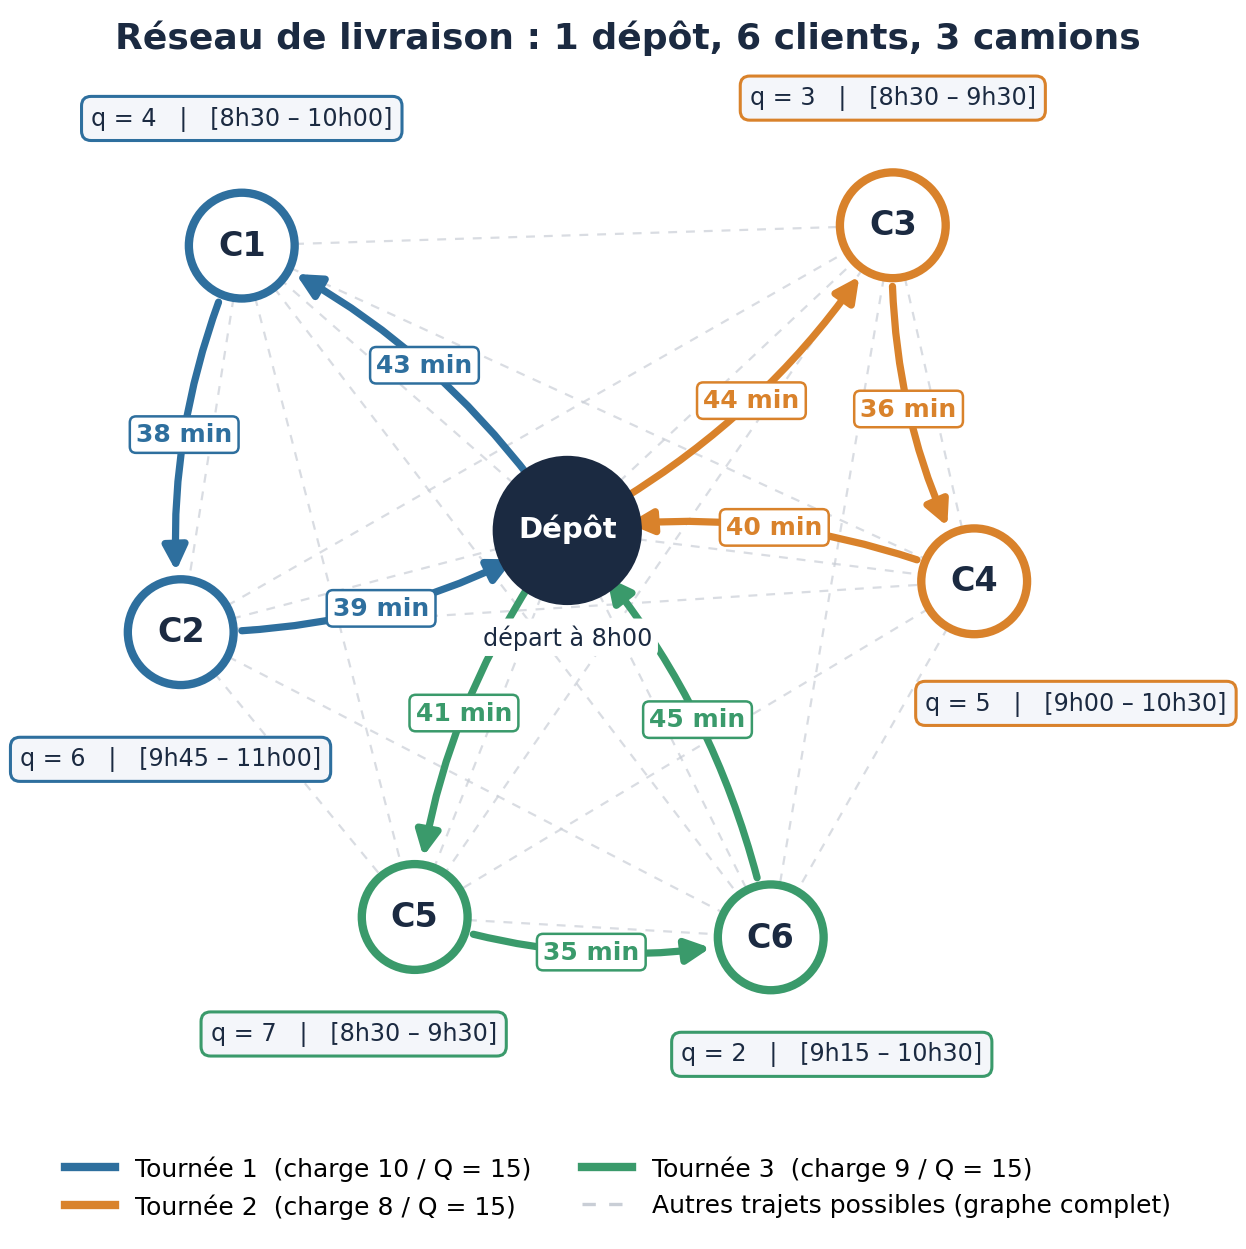

*Figure 1 – Exemple de graphe : 1 dépôt, 6 clients et 3 tournées (une couleur par camion)*

> **Comment lire la figure 1**
>
> - Le **disque sombre** est le dépôt. Les **cercles** sont les clients. Chaque cadre indique la demande $q$ et la fenêtre de temps du client.
> - Les **flèches colorées** forment les tournées. Le nombre sur chaque flèche est le temps de trajet en minutes.
> - Les **traits gris pointillés** rappellent que toutes les autres liaisons sont possibles : c'est ce qui rend le graphe complet.

Le tableau suivant résume les trois tournées de cet exemple. On vérifie bien que la charge de chaque camion reste inférieure ou égale à $Q = 15$. Il s'agit d'une solution **réalisable**, mais nous ne prétendons pas qu'elle soit la meilleure possible.

| Tournée | Trajet | Charge | Conduite | Retour au dépôt |
|:---:|---|:---:|:---:|---|
| 1 | Dépôt → C1 → C2 → Dépôt | 10 / 15 | 120 min | 10h34 (dont 14 min d'attente) |
| 2 | Dépôt → C3 → C4 → Dépôt | 8 / 15 | 120 min | 10h20 |
| 3 | Dépôt → C5 → C6 → Dépôt | 9 / 15 | 121 min | 10h21 |
| **Total** | 3 tournées, 6 clients livrés | 27 | ≈ 361 min | |

Le tableau est recalculé ci-dessous à partir des données, ce qui permet de le vérifier.

In [2]:
print(f"{'Tournée':<8} {'Trajet':<26} {'Charge':>7} {'Conduite':>9} {'Retour':>7} {'Attente':>8}")
total_conduite, total_charge = 0, 0
for num, tour in enumerate(tournees, 1):
    charge = sum(clients[c][0] for c in tour)
    heure, pos, conduite, attente = depart_depot, "D", 0, 0
    for c in tour:
        heure += t[(pos, c)]
        conduite += t[(pos, c)]
        debut = max(heure, clients[c][1])          # attente si arrivée avant a_i
        attente += debut - heure
        heure = debut + service
        pos = c
    heure += t[(pos, "D")]
    conduite += t[(pos, "D")]
    trajet = " → ".join(["Dépôt"] + tour + ["Dépôt"])
    print(f"{num:<8} {trajet:<26} {charge:>4}/{Q} {conduite:>6} min {fmt(heure):>7} {attente:>5} min")
    total_conduite += conduite
    total_charge += charge
print(f"{'Total':<8} {'':<26} {total_charge:>7} {total_conduite:>6} min")

Tournée  Trajet                      Charge  Conduite  Retour  Attente
1        Dépôt → C1 → C2 → Dépôt      10/15    120 min   10h34    14 min
2        Dépôt → C3 → C4 → Dépôt       8/15    120 min   10h20     0 min
3        Dépôt → C5 → C6 → Dépôt       9/15    121 min   10h21     0 min
Total                                    27    361 min


## 5. Les contraintes

Une solution n'est acceptable que si elle respecte **toutes** les contraintes suivantes :

| # | Contrainte | Règle |
|:---:|---|---|
| 1 | **Visite unique** | Chaque client est livré exactement une fois, par un seul camion. |
| 2 | **Dépôt** | Chaque tournée commence et finit au dépôt. |
| 3 | **Capacité** | Pour chaque camion, la somme des demandes $q_i$ des clients livrés est $\le Q$. |
| 4 | **Fenêtre de temps** | Le service chez le client $i$ doit **commencer entre $a_i$ et $b_i$**. Si le camion arrive avant $a_i$, il **attend** l'ouverture. S'il arrive après $b_i$, c'est **interdit**. |
| 5 | **Nombre de camions** | On utilise au plus $k$ camions. |

### 5.1 La contrainte de fenêtre de temps en détail

C'est la seule contrainte ajoutée à la version de base, et c'est elle qui rend le problème plus réaliste. Elle se résume par une règle :

> **Règle de la fenêtre de temps**
>
> Heure de début du service = **le plus grand** entre l'heure d'arrivée et $a_i$ :
> $$\text{début}_i = \max(\text{arrivée}_i,\ a_i)$$
> Cette heure de début doit être **inférieure ou égale à $b_i$**, sinon la tournée est interdite.

Voici ce qui se passe pour le camion 1 de notre exemple (figure 2). Il arrive chez C2 à **9h31**, mais la fenêtre de C2 ne s'ouvre qu'à **9h45**. Il attend donc **14 minutes**, puis il livre de 9h45 à 9h55. Il repart ensuite vers le dépôt, où il arrive à 10h34. S'il était arrivé chez C2 à 11h10, après la fermeture de 11h00, la livraison aurait été interdite : il aurait fallu changer l'ordre des clients ou les répartir autrement.

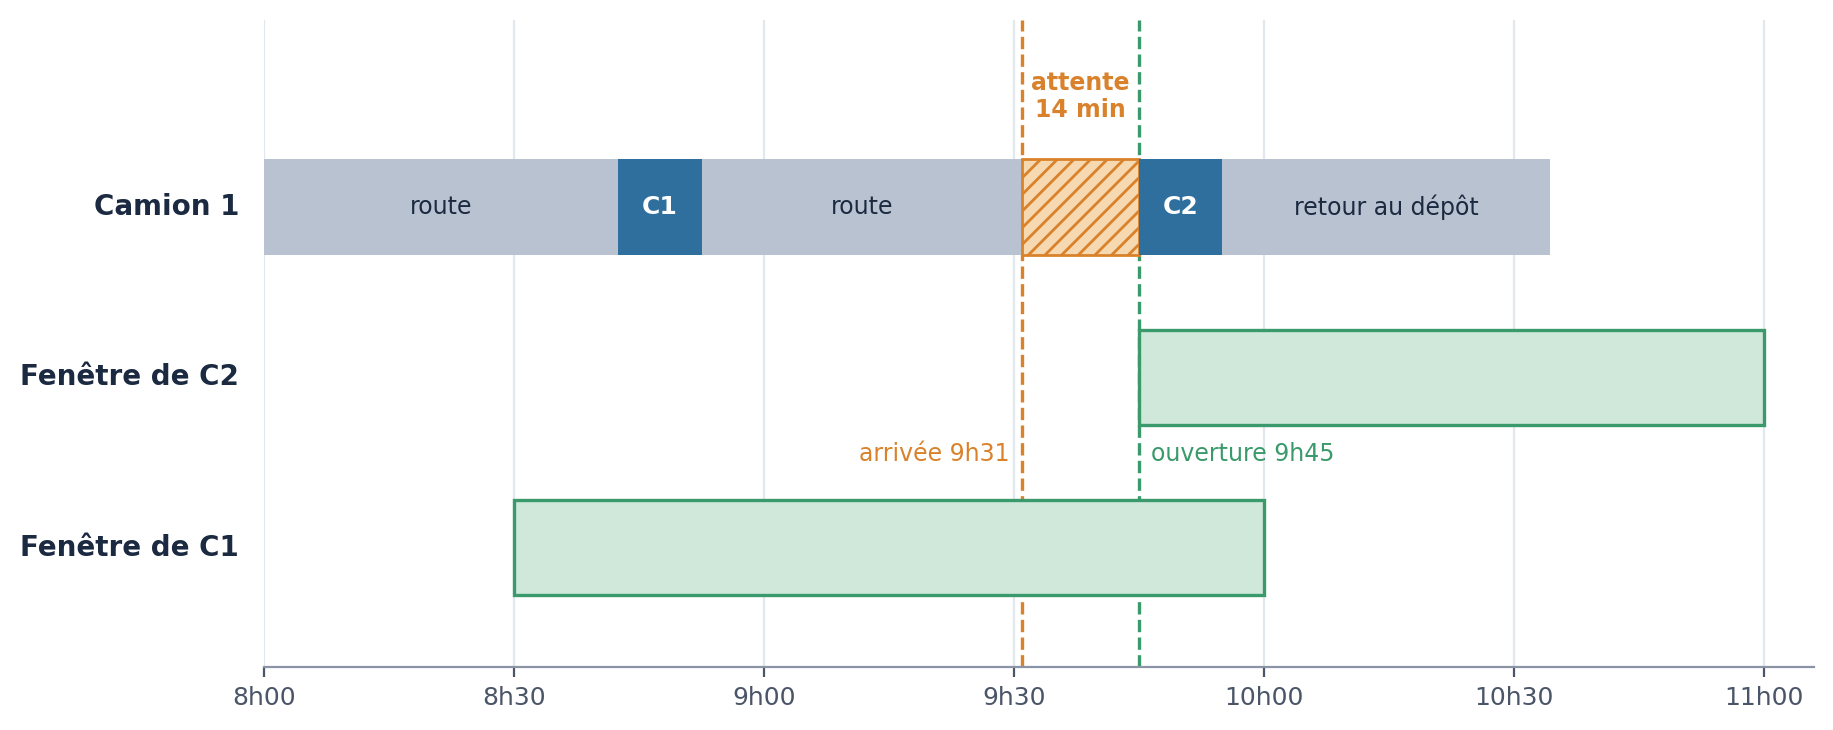

*Figure 2 – Déroulement de la tournée 1 : attente avant l'ouverture de la fenêtre de C2*

In [3]:
# Déroulement détaillé de la tournée 1 (règle de la fenêtre de temps)
heure, pos = depart_depot, "D"
print(f"{fmt(heure)}  départ du dépôt")
for c in tournees[0]:
    q, a, b = clients[c]
    heure += t[(pos, c)]
    debut = max(heure, a)
    etat = "OK" if debut <= b else "INTERDIT (après b)"
    print(f"{fmt(heure)}  arrivée chez {c}  fenêtre [{fmt(a)}, {fmt(b)}]"
          + (f"  ->  attente {debut - heure} min" if debut > heure else ""))
    print(f"{fmt(debut)}  début du service chez {c}  ({etat})")
    heure, pos = debut + service, c
heure += t[(pos, "D")]
print(f"{fmt(heure)}  retour au dépôt")

8h00  départ du dépôt
8h43  arrivée chez C1  fenêtre [8h30, 10h00]
8h43  début du service chez C1  (OK)
9h31  arrivée chez C2  fenêtre [9h45, 11h00]  ->  attente 14 min
9h45  début du service chez C2  (OK)
10h34  retour au dépôt


## 6. L'objectif à optimiser

Parmi toutes les solutions qui respectent les contraintes, on cherche celle dont le **temps de conduite total** est le plus petit. On additionne les temps de trajet $t_{ij}$ de tous les arcs empruntés par les camions :

$$
\text{minimiser} \sum_{(i,j)\ \text{empruntés}} t_{ij}
$$

Dans l'exemple, la conduite totale est d'environ **361 minutes**.

**Deux remarques :**

1. **Trafic.** L'énoncé mentionne un trafic qui dépend de la tranche horaire. Pour ce premier livrable, nous prenons des temps $t_{ij}$ constants, ce qui simplifie la modélisation et pourra être discuté avec le tuteur. Pour l'intégrer plus tard, $t_{ij}$ deviendra une fonction de l'heure de départ $t_{ij}(h)$. Il faudra alors respecter la propriété **FIFO** : *partir plus tard ne doit jamais faire arriver plus tôt*. On l'obtient en fixant une **vitesse** par tranche horaire plutôt qu'une durée (Ichoua, Gendreau et Potvin, 2003).
2. **Attente.** On pourrait aussi inclure les temps d'attente dans l'objectif, selon ce que l'ADEME juge le plus important. Nous gardons le temps de conduite : c'est lui qui consomme du carburant, et c'est le critère des instances de référence (vrplib) qui serviront au calcul du gap.

## 7. Combien de solutions possibles ?

Une première idée serait de **tout essayer** : énumérer toutes les solutions, calculer le coût de chacune, garder la meilleure. Voyons si c'est raisonnable.

Avec $n$ clients, l'ordre de passage peut se choisir de **$n!$ façons** (« factorielle de $n$ »). Par exemple, pour 3 clients, il y a $3! = 3 \times 2 \times 1 = 6$ ordres possibles. En plus, il faut décider où couper cet ordre pour former les tournées des différents camions, ce qui augmente encore le nombre de solutions. Le nombre $n!$ donne donc déjà un bon ordre de grandeur.

| Clients ($n$) | Nombre d'ordres : $n!$ | Temps pour tout tester (1 milliard de solutions par seconde) |
|:---:|---|---|
| 5 | 120 | instantané |
| 10 | 3 628 800 | environ 4 millièmes de seconde |
| 15 | $1{,}3 \times 10^{12}$ | environ 22 minutes |
| 20 | $2{,}4 \times 10^{18}$ | environ 77 ans |
| 25 | $1{,}6 \times 10^{25}$ | environ 490 millions d'années |
| 1 000 | un nombre de 2 568 chiffres | impossible |

Le tableau est recalculé ci-dessous, puis tracé : l'échelle verticale est logarithmique, chaque graduation multiplie le temps par 10.

n =  5   n! = 1.20e+02   ->  0.0 ms
n = 10   n! = 3.63e+06   ->  3.6 ms
n = 15   n! = 1.31e+12   ->  22 min
n = 20   n! = 2.43e+18   ->  77 ans
n = 25   n! = 1.55e+25   ->  491 520 586 ans
n = 1000  n! a 2568 chiffres


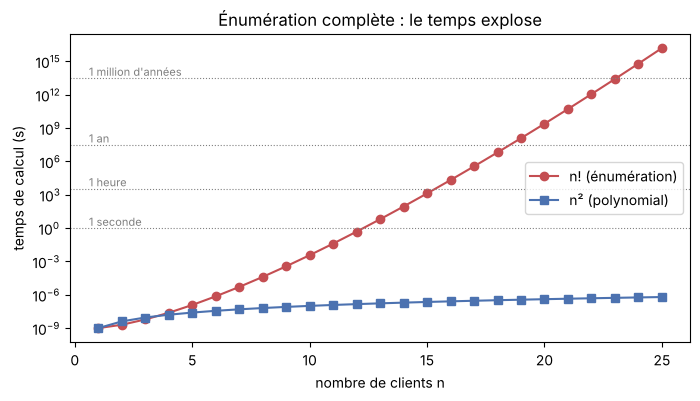

In [4]:
import math
import matplotlib.pyplot as plt

VITESSE = 1e9                       # solutions testées par seconde
AN = 365.25 * 24 * 3600

def duree(secondes):
    if secondes < 1:
        return f"{secondes * 1000:.1f} ms"
    if secondes < 3600:
        return f"{secondes / 60:.0f} min"
    if secondes < AN:
        return f"{secondes / 86400:.0f} jours"
    return f"{secondes / AN:,.0f} ans".replace(",", " ")

for n in (5, 10, 15, 20, 25):
    f = math.factorial(n)
    print(f"n = {n:>2}   n! = {f:.2e}   ->  {duree(f / VITESSE)}")
print(f"n = 1000  n! a {len(str(math.factorial(1000)))} chiffres")

ns = list(range(1, 26))
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(ns, [math.factorial(n) / VITESSE for n in ns], "o-", color="#c44e52",
            label="n! (énumération)")
ax.semilogy(ns, [n**2 / VITESSE for n in ns], "s-", color="#4c72b0", label="n² (polynomial)")
for y, nom in [(1, "1 seconde"), (3600, "1 heure"), (AN, "1 an"), (1e6 * AN, "1 million d'années")]:
    ax.axhline(y, color="grey", lw=0.8, ls=":")
    ax.text(0.6, y * 1.6, nom, fontsize=8, color="grey")
ax.set_xlabel("nombre de clients n")
ax.set_ylabel("temps de calcul (s)")
ax.set_title("Énumération complète : le temps explose")
ax.legend()
plt.show()

**Conclusion** : l'énumération complète est possible pour une dizaine de clients, mais **impossible dès 20 clients**. Or notre objectif est de traiter **plusieurs milliers de villes**. Il faut donc une méthode beaucoup plus intelligente, et pour la choisir, il faut d'abord comprendre **à quel point le problème est difficile**. C'est le rôle de l'étude de complexité.

## 8. Classe du problème et complexité

### 8.1 Les notions à connaître

La **complexité** mesure comment le temps de calcul d'un algorithme grandit quand la taille $n$ du problème augmente. On distingue deux familles :

| Famille | Croissance | Exemple chiffré |
|---|---|---|
| **Temps polynomial** | $n^2$, $n^3$... C'est « rapide ». | $n = 1\,000$ et un temps en $n^2$ : environ un million d'opérations, soit une fraction de seconde. |
| **Temps exponentiel** | $2^n$, $n!$... Le temps explose. | $n = 100$ et un temps en $2^n$ : environ $10^{30}$ opérations, impossible. |

Les informaticiens classent les problèmes en **classes**. Pour cela, ils utilisent des problèmes de **décision**, c'est-à-dire des questions dont la réponse est **oui ou non**. Un problème d'optimisation (« trouver la meilleure tournée ») se transforme en problème de décision en fixant un seuil $L$ (« existe-t-il une tournée de coût inférieur ou égal à $L$ ? »).

| Classe | Définition simple | Exemples |
|---|---|---|
| **P** | On sait **trouver** la réponse en temps polynomial. | Trier une liste ; trouver le plus court chemin entre deux points (algorithme de Dijkstra) |
| **NP** | On sait **vérifier** une solution proposée en temps polynomial (même si la trouver peut être long). | Sudoku : difficile à résoudre, immédiat à vérifier |
| **NP-complet** | Dans NP, et au moins aussi difficile que tous les autres problèmes de NP. | TSP (version décision), SAT |
| **NP-difficile** | Au moins aussi difficile que les problèmes NP-complets (sans être forcément dans NP). | TSP et CVRPTW en version optimisation |

Une question ouverte célèbre est de savoir si **P = NP** : on ne sait pas s'il existe un algorithme rapide pour les problèmes NP-complets. La grande majorité des chercheurs pense que non. Nous raisonnons donc avec l'hypothèse **P ≠ NP**.

### 8.2 Le problème de décision associé

> **CVRPTW – version décision**
>
> **Entrée** : le graphe $G$, les demandes $q_i$, les fenêtres $[a_i, b_i]$, les durées de service $s_i$, $k$, $Q$ et un seuil $L$.
>
> **Question** : existe-t-il au plus $k$ tournées respectant toutes les contraintes et dont le temps de conduite total est $\le L$ ?

### 8.3 Étape 1 : le problème est dans NP

Supposons qu'un collègue nous propose des tournées. Peut-on vérifier rapidement qu'elles conviennent ? Oui. Pour chaque tournée, on parcourt les clients dans l'ordre et on contrôle :

1. chaque client apparaît exactement une fois ;
2. la charge cumulée reste $\le Q$ ;
3. en simulant l'horloge, on vérifie que chaque service commence dans sa fenêtre ;
4. la somme des temps de trajet est $\le L$.

On ne fait qu'un seul passage sur les $n$ clients : le temps est proportionnel à $n$, donc **polynomial**. Le problème est bien **dans NP**.

Le vérificateur ci-dessous applique exactement ces quatre contrôles.

In [5]:
def verifier(tournees, L):
    # Vérificateur en O(n) : renvoie True si la réponse au problème de décision est « oui » pour ces tournées.
    erreurs = []
    vus = [c for tour in tournees for c in tour]
    if sorted(vus) != sorted(clients):                       # contrôle 1
        erreurs.append("un client manque ou est livré deux fois")
    if len(tournees) > k:
        erreurs.append(f"{len(tournees)} tournées pour {k} camions")
    total = 0
    for tour in tournees:
        if sum(clients[c][0] for c in tour) > Q:              # contrôle 2
            erreurs.append(f"capacité dépassée sur {tour}")
        heure, pos = depart_depot, "D"
        for c in tour:                                        # contrôle 3
            heure += t[(pos, c)]
            total += t[(pos, c)]
            debut = max(heure, clients[c][1])
            if debut > clients[c][2]:
                erreurs.append(f"{c} servi à {fmt(debut)}, après {fmt(clients[c][2])}")
            heure, pos = debut + service, c
        total += t[(pos, "D")]
    if total > L:                                             # contrôle 4
        erreurs.append(f"coût {total} > L = {L}")
    print(("OUI" if not erreurs else "NON") + f"  (coût = {total} min, seuil L = {L})")
    for e in erreurs:
        print("  -", e)
    return not erreurs


verifier(tournees, L=361)
print()
verifier(tournees, L=350)

OUI  (coût = 361 min, seuil L = 361)

NON  (coût = 361 min, seuil L = 350)
  - coût 361 > L = 350


False

### 8.4 Étape 2 : le problème est NP-difficile (réduction depuis le TSP)

Pour prouver qu'un problème est difficile, on utilise une **réduction polynomiale**. L'idée est la suivante : on prend un problème qu'on sait déjà très difficile (ici le **TSP**, ou problème du voyageur de commerce), et on montre qu'il se **cache à l'intérieur** de notre problème. Si on savait résoudre notre problème rapidement, on saurait alors résoudre le TSP rapidement, ce qui n'est pas le cas. Notre problème est donc au moins aussi difficile.

**Le TSP (version décision).** On a $n$ villes, les distances $d_{ij}$ entre elles, et un seuil $L$. Question : existe-t-il un circuit qui passe **une fois par chaque ville** et revient au point de départ, de longueur $\le L$ ? Ce problème est NP-complet (Karp, 1972 ; Garey et Johnson, 1979).

**La réduction.** À partir d'une instance du TSP, on construit en temps polynomial une instance du CVRPTW :

| # | Instance TSP | Instance CVRPTW construite |
|:---:|---|---|
| 1 | une ville quelconque | le **dépôt** |
| 1 | les autres villes | les **clients** |
| 2 | un seul voyageur | $k = 1$ camion |
| 3 | pas de notion de charge | $q_i = 1$ et $Q = n$ : le camion peut tout porter, la capacité ne gêne jamais |
| 4 | pas de notion d'horaire | fenêtres $[0, M]$ avec $M$ très grand (par exemple la somme de toutes les distances) et $s_i = 0$ : elles ne gênent jamais non plus |
| 5 | distances $d_{ij}$, seuil $L$ | $t_{ij} = d_{ij}$, même seuil $L$ |

**Pourquoi ça marche.**

- **TSP « oui » ⇒ CVRPTW « oui ».** Un circuit du TSP de longueur $\le L$ donne directement une solution du CVRPTW : l'unique camion suit ce circuit.
- **CVRPTW « oui » ⇒ TSP « oui ».** Une solution du CVRPTW avec $k = 1$ est un unique circuit qui visite chaque client une fois et revient au dépôt : c'est un circuit du TSP de longueur $\le L$.

Les deux problèmes ont donc **exactement les mêmes réponses**. La construction ne demande que de recopier les données (de l'ordre de $n^2$ opérations), donc elle est polynomiale.

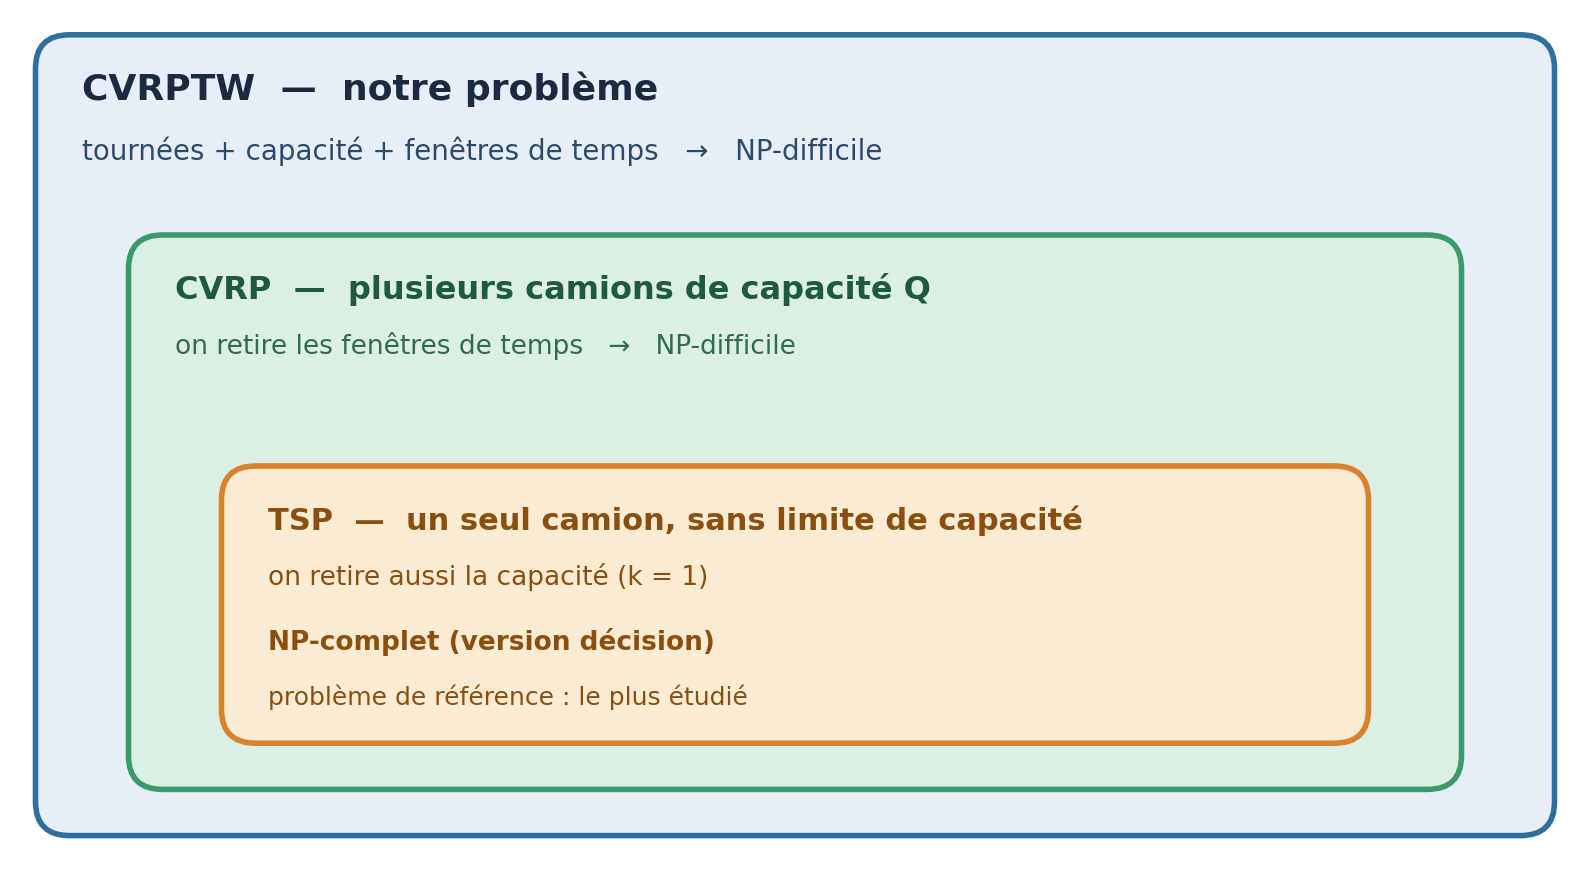

*Figure 3 – Le TSP est un cas particulier du CVRP, lui-même un cas particulier du CVRPTW*

### 8.5 Conclusion de l'étude de complexité

> **Résultat**
>
> - Le CVRPTW (version décision) est **dans NP** (étape 1) et **NP-difficile** (étape 2) : il est donc **NP-complet**.
> - Sa version d'optimisation (« trouver la tournée de coût minimal ») est **NP-difficile**.
> - Les fenêtres de temps rendent le problème encore plus dur en pratique : dès $k = 1$, même **trouver une solution réalisable** est NP-difficile (cas du TSPTW, Savelsbergh, 1985), alors que sans fenêtres, tout ordre des clients est toujours réalisable.

## 9. Modèle PLNE (première version)

Le livrable demande une première modélisation sous forme de **Programme Linéaire en Nombres Entiers** : variables de décision, fonction objectif, contraintes. On reprend les notations de la section 3. On note $V^* = \{1, \dots, n\}$ l'ensemble des clients.

### 9.1 Variables de décision

| Variable | Type | Signification |
|---|---|---|
| $x_{ij}$ | binaire (0 ou 1) | vaut 1 si un camion va directement de $i$ à $j$, pour tout arc $(i, j) \in A$ |
| $u_i$ | réelle | charge déjà livrée par le camion après son passage chez le client $i$ |
| $T_i$ | réelle | heure de **début du service** chez le client $i$ |

Les camions sont identiques, on n'a donc pas besoin de les numéroter : $x_{ij}$ n'a que deux indices. Un indice camion ($x_{ijk}$) multiplierait le nombre de variables par $k$ et créerait des solutions équivalentes (échanger deux camions), ce qui ralentit la résolution.

### 9.2 Fonction objectif

$$
\min \sum_{(i,j) \in A} t_{ij}\, x_{ij} \tag{0}
$$

C'est la formule de la section 6 : on additionne $t_{ij}$ seulement pour les arcs empruntés ($x_{ij} = 1$).

### 9.3 Contraintes

**Visite unique (contrainte 1)** : chaque client a exactement un arc entrant et un arc sortant.

$$
\sum_{i \in V,\, i \neq j} x_{ij} = 1 \quad \forall j \in V^* \tag{1a}
$$
$$
\sum_{j \in V,\, j \neq i} x_{ij} = 1 \quad \forall i \in V^* \tag{1b}
$$

**Dépôt et nombre de camions (contraintes 2 et 5)** : au plus $k$ camions partent du dépôt, et autant y reviennent.

$$
\sum_{j \in V^*} x_{0j} \le k \tag{5}
$$
$$
\sum_{j \in V^*} x_{0j} = \sum_{i \in V^*} x_{i0} \tag{2}
$$

**Capacité (contrainte 3)**, avec les contraintes MTZ (Miller, Tucker et Zemlin, 1960) :

$$
u_j \ge u_i + q_j - Q\,(1 - x_{ij}) \quad \forall i, j \in V^*,\ i \neq j \tag{3a}
$$
$$
q_i \le u_i \le Q \quad \forall i \in V^* \tag{3b}
$$

**Fenêtres de temps (contrainte 4)** :

$$
T_j \ge T_i + s_i + t_{ij} - M_{ij}\,(1 - x_{ij}) \quad \forall i, j \in V^*,\ i \neq j \tag{4a}
$$
$$
T_j \ge a_0 + t_{0j}\, x_{0j} \quad \forall j \in V^* \tag{4b}
$$
$$
T_i + s_i + t_{i0} \le b_0 + M_{i0}\,(1 - x_{i0}) \quad \forall i \in V^* \tag{4c}
$$
$$
a_i \le T_i \le b_i \quad \forall i \in V^* \tag{4d}
$$

$[a_0, b_0]$ sont les heures d'ouverture du dépôt (départ à 8h00 dans l'exemple).

**Nature des variables** :

$$
x_{ij} \in \{0, 1\} \quad \forall (i,j) \in A \tag{6}
$$

### 9.4 Comment lire ces contraintes

| Contrainte | Ce qu'elle fait |
|---|---|
| (1a), (1b) | Une entrée et une sortie par client : il est visité une fois. |
| (2), (5) | Au plus $k$ tournées, chacune part du dépôt et y revient. |
| (3a) | **Interrupteur.** Si $x_{ij} = 1$ : $u_j \ge u_i + q_j$, la charge augmente de la demande de $j$. Si $x_{ij} = 0$ : le terme $-Q$ rend la contrainte toujours vraie, donc inactive. |
| (3b) | La charge ne dépasse jamais $Q$ : c'est la capacité. |
| (3a) bis | Elle **interdit aussi les sous-tours**. Un circuit $1 \to 2 \to 3 \to 1$ sans le dépôt respecterait (1a) et (1b), mais il imposerait $u_1 < u_2 < u_3 < u_1$, ce qui est impossible. Seul le dépôt, qui n'a pas de $u$, permet de repartir à zéro. |
| (4a) | **Interrupteur** sur le temps : si $j$ suit $i$, on ne commence pas chez $j$ avant d'avoir fini chez $i$ et roulé jusqu'à $j$. |
| (4b), (4c) | Départ du dépôt après son ouverture, retour avant sa fermeture. |
| (4d) | Le service commence dans la fenêtre. La borne $T_i \le b_i$ **interdit le retard**. |

**L'attente est autorisée** parce que (4a) est un « $\ge$ » et non un « $=$ ». Si le camion arrive avant $a_j$, (4d) repousse simplement $T_j$ jusqu'à $a_j$. C'est la règle $\max(\text{arrivée}, a_i)$ de la section 5.1, écrite de façon linéaire.

### 9.5 Le choix des grands nombres $M$

Un $M$ trop grand (par exemple $10^9$) affaiblit le modèle et provoque des erreurs numériques. On prend la plus petite valeur qui rend la contrainte inactive quand $x_{ij} = 0$. Le pire cas est de partir de $i$ au plus tard ($T_i = b_i$) et d'arriver en $j$ au plus tôt ($T_j = a_j$) :

$$
M_{ij} = \max(0,\ b_i + s_i + t_{ij} - a_j) \qquad M_{i0} = \max(0,\ b_i + s_i + t_{i0} - b_0)
$$

### 9.6 Arcs impossibles

Certains arcs ne seront jamais utilisés, on peut fixer $x_{ij} = 0$ d'avance :

| Raison | Condition |
|---|---|
| Temps | $a_i + s_i + t_{ij} > b_j$ : même en partant au plus tôt de $i$, on arrive trop tard chez $j$. |
| Capacité | $q_i + q_j > Q$ : les deux clients ne tiennent pas dans un même camion. |

Dans l'exemple, C3 et C5 ferment à 9h30. Partir de C3 au plus tôt (8h30 + 10 min de service) puis rouler vers C5 dépasse 9h30 dès que le trajet fait plus de 50 min : l'arc C3 → C5 serait alors supprimé.

### 9.7 Taille du modèle

| Élément | Nombre |
|---|---|
| Variables binaires $x_{ij}$ | $n(n+1)$ |
| Variables réelles $u_i$, $T_i$ | $2n$ |
| Contraintes | environ $2n^2$ |

Pour l'exemple ($n = 6$) : 42 variables binaires. Pour 1 000 clients : environ un million. La taille croît en $n^2$, donc le modèle reste **écrivable** même pour de grandes instances. C'est le **temps de résolution** qui explose, comme l'a montré la section 8.

## 10. Conséquences pour la suite du projet

Cette étude oriente nos choix pour les prochaines étapes :

| Étape | Rôle |
|---|---|
| **Méthodes exactes** | Le modèle PLNE de la section 9 donne un modèle mathématique rigoureux. Un solveur pourra le résoudre pour de **petites instances**, ce qui fournit des solutions de référence et des bornes. |
| **Métaheuristiques** | Pour plusieurs milliers de clients, on utilisera une méthode qui cherche une **très bonne solution sans garantie d'optimalité** (recuit simulé, recherche tabou, ALNS...). C'est la seule voie réaliste pour un problème NP-difficile de grande taille. |
| **Validation** | Nous comparerons nos résultats aux meilleures solutions connues des instances de référence (bibliothèque vrplib) avec le calcul du gap. |
| **Application** | La version finale sera réalisée sous forme d'application. Le travail de modélisation et de complexité présenté ici en est le socle théorique. |

**Points à valider avec le tuteur**

1. Temps de trajet constants dans ce premier modèle (trafic traité plus tard).
2. Objectif : temps de conduite, sans les temps d'attente.
3. Modèle PLNE de la section 9 : variables à deux indices et contraintes MTZ.

## 11. Glossaire

| Terme | Signification |
|---|---|
| VRP | *Vehicle Routing Problem* : problème de tournées de véhicules. |
| CVRP | VRP avec capacité (*Capacitated*) : chaque camion a une charge maximale $Q$. |
| CVRPTW | CVRP avec fenêtres de temps (*Time Windows*) : notre problème. |
| TSP | *Traveling Salesman Problem* : un seul véhicule doit visiter toutes les villes une fois. |
| Graphe orienté complet | Sommets reliés deux à deux par des flèches dans les deux sens. |
| Réduction polynomiale | Transformation rapide d'un problème A en un problème B, qui montre que B est au moins aussi difficile que A. |
| Heuristique / métaheuristique | Méthode qui trouve une bonne solution rapidement, sans garantir que ce soit la meilleure. |
| PLNE | Programme linéaire en nombres entiers : modèle mathématique avec variables entières, un objectif et des contraintes linéaires. |
| Sous-tour | Circuit qui ne passe pas par le dépôt : aucun camion ne peut le réaliser. |
| MTZ | Contraintes de Miller, Tucker et Zemlin, qui interdisent les sous-tours. |
| FIFO | *First In, First Out* : partir plus tard ne fait jamais arriver plus tôt. |

## 12. Références

1. Dantzig, G. B. et Ramser, J. H. (1959). The truck dispatching problem. *Management Science*, 6(1), 80-91.
2. Miller, C. E., Tucker, A. W. et Zemlin, R. A. (1960). Integer programming formulation of traveling salesman problems. *Journal of the ACM*, 7(4), 326-329.
3. Karp, R. M. (1972). Reducibility among combinatorial problems. Dans *Complexity of Computer Computations*, Plenum Press, pp. 85-103.
4. Garey, M. R. et Johnson, D. S. (1979). *Computers and Intractability: A Guide to the Theory of NP-Completeness*. W. H. Freeman.
5. Savelsbergh, M. W. P. (1985). Local search in routing problems with time windows. *Annals of Operations Research*, 4, 285-305.
6. Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
7. Ichoua, S., Gendreau, M. et Potvin, J.-Y. (2003). Vehicle dispatching with time-dependent travel times. *European Journal of Operational Research*, 144(2), 379-396.
8. Toth, P. et Vigo, D. (2014). *Vehicle Routing: Problems, Methods, and Applications* (2e éd.). SIAM.